In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Machine Learning libraries
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

import joblib

print("All libraries imported successfully!")

# Project directory
PROJECT_DIR = (
    Path.home()
    / "Documents"
    / "Internship"
    / "Week 6 Capstone Project"
)

# File paths
DATA_PATH = PROJECT_DIR / "data" / "raw" / "Telco-Customer-Churn.csv"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

# Create output directories
for folder in [PROCESSED_DIR, OUTPUT_DIR, FIGURE_DIR, MODEL_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Verify dataset
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# Load original dataset
df_original = pd.read_csv(DATA_PATH)
df = df_original.copy()

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Dataset location:", DATA_PATH)

display(df.head())


All libraries imported successfully!

Dataset loaded successfully!
Dataset shape: (7043, 21)
Dataset location: /Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/data/raw/Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [27]:

# ============================================================
# CELL 2: DATA CLEANING AND PREPROCESSING
# ============================================================

# Remove unnecessary whitespace from text columns
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

print("Original shape:", df.shape)

# Check duplicate customer IDs
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# Remove duplicate customer records, if any
df = df.drop_duplicates(subset="customerID", keep="first")

# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Investigate missing TotalCharges
missing_total = df["TotalCharges"].isna()

print("\nMissing TotalCharges:", missing_total.sum())

if missing_total.sum() > 0:

    missing_tenure = df.loc[missing_total, "tenure"]

    print("Tenure values of affected customers:")
    print(missing_tenure.value_counts())

    # Blank TotalCharges in the original dataset are associated
    # with customers having zero tenure.
    if len(missing_tenure) > 0 and (missing_tenure == 0).all():
        df.loc[missing_total, "TotalCharges"] = 0
        print("Filled valid zero-tenure TotalCharges with 0.")
    else:
        median_value = df["TotalCharges"].median()
        df["TotalCharges"] = df["TotalCharges"].fillna(median_value)
        print("Filled remaining TotalCharges using median.")

# Standardize target values
df["Churn"] = df["Churn"].str.strip().str.title()

# Remove missing target records
df = df.dropna(subset=["Churn"]).copy()

# Encode target
df["Churn_Binary"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

if df["Churn_Binary"].isna().any():
    raise ValueError("Unexpected values found in Churn column.")

df["Churn_Binary"] = df["Churn_Binary"].astype(int)

# Save cleaned dataset
cleaned_path = PROCESSED_DIR / "Telco_Customer_Churn_Cleaned.csv"
df.to_csv(cleaned_path, index=False)

print("\nDATA CLEANING COMPLETED")
print("Final dataset shape:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

print("\nChurn target distribution:")
display(df["Churn"].value_counts())

print("\nCleaned dataset saved:", cleaned_path)


Original shape: (7043, 21)
Duplicate customer IDs: 0

Missing TotalCharges: 11
Tenure values of affected customers:
tenure
0    11
Name: count, dtype: int64
Filled valid zero-tenure TotalCharges with 0.

DATA CLEANING COMPLETED
Final dataset shape: (7043, 22)
Missing values remaining: 0
Duplicate customer IDs: 0

Churn target distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Cleaned dataset saved: /Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/data/processed/Telco_Customer_Churn_Cleaned.csv


In [28]:

# ============================================================
# CELL 3: DATA QUALITY REPORT
# ============================================================

quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2),
    "Unique Values": df.nunique()
})

display(quality_report)

quality_report.to_csv(
    OUTPUT_DIR / "data_quality_report.csv"
)

print("\nNumerical summary:")
display(df.describe())

print("\nCategorical summary:")
display(df.describe(include="object").T)

print("\nData quality report exported successfully!")


,Data Type,Missing Values,Missing Percentage,Unique Values
customerID,str,0,0.0,7043
gender,str,0,0.0,2
SeniorCitizen,int64,0,0.0,2
Partner,str,0,0.0,2
Dependents,str,0,0.0,2
tenure,int64,0,0.0,73
PhoneService,str,0,0.0,2
MultipleLines,str,0,0.0,3
InternetService,str,0,0.0,3
OnlineSecurity,str,0,0.0,3



Numerical summary:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_Binary
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,0.265370
std,0.368612,24.559481,30.090047,2266.794470,0.441561
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,0.000000
50%,0.000000,29.000000,70.350000,1394.550000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000



Categorical summary:


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095



Data quality report exported successfully!


,Customer Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


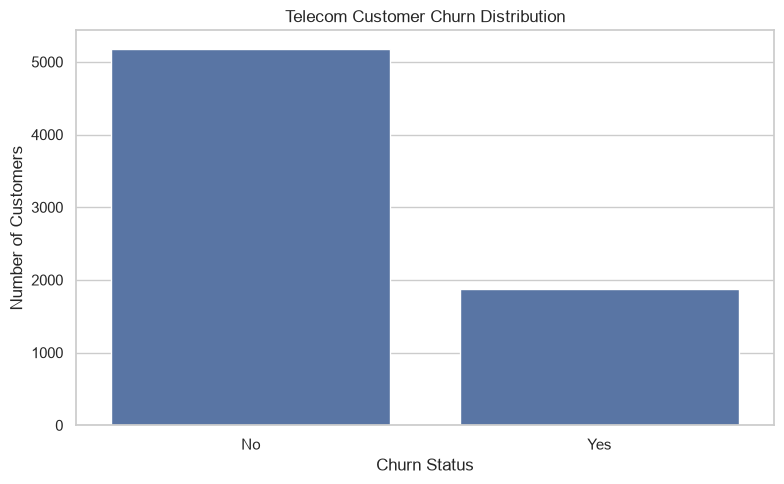

Overall churn rate: 26.54 %


In [29]:

# ============================================================
# CELL 4: CUSTOMER CHURN DISTRIBUTION
# ============================================================

churn_counts = df["Churn"].value_counts()

churn_percentages = (
    df["Churn"].value_counts(normalize=True) * 100
)

churn_summary = pd.DataFrame({
    "Customer Count": churn_counts,
    "Percentage": churn_percentages.round(2)
})

display(churn_summary)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Churn",
    order=["No", "Yes"]
)

plt.title("Telecom Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "01_churn_distribution.png",
    dpi=300
)

plt.show()

print("Overall churn rate:", round(churn_percentages.get("Yes", 0), 2), "%")


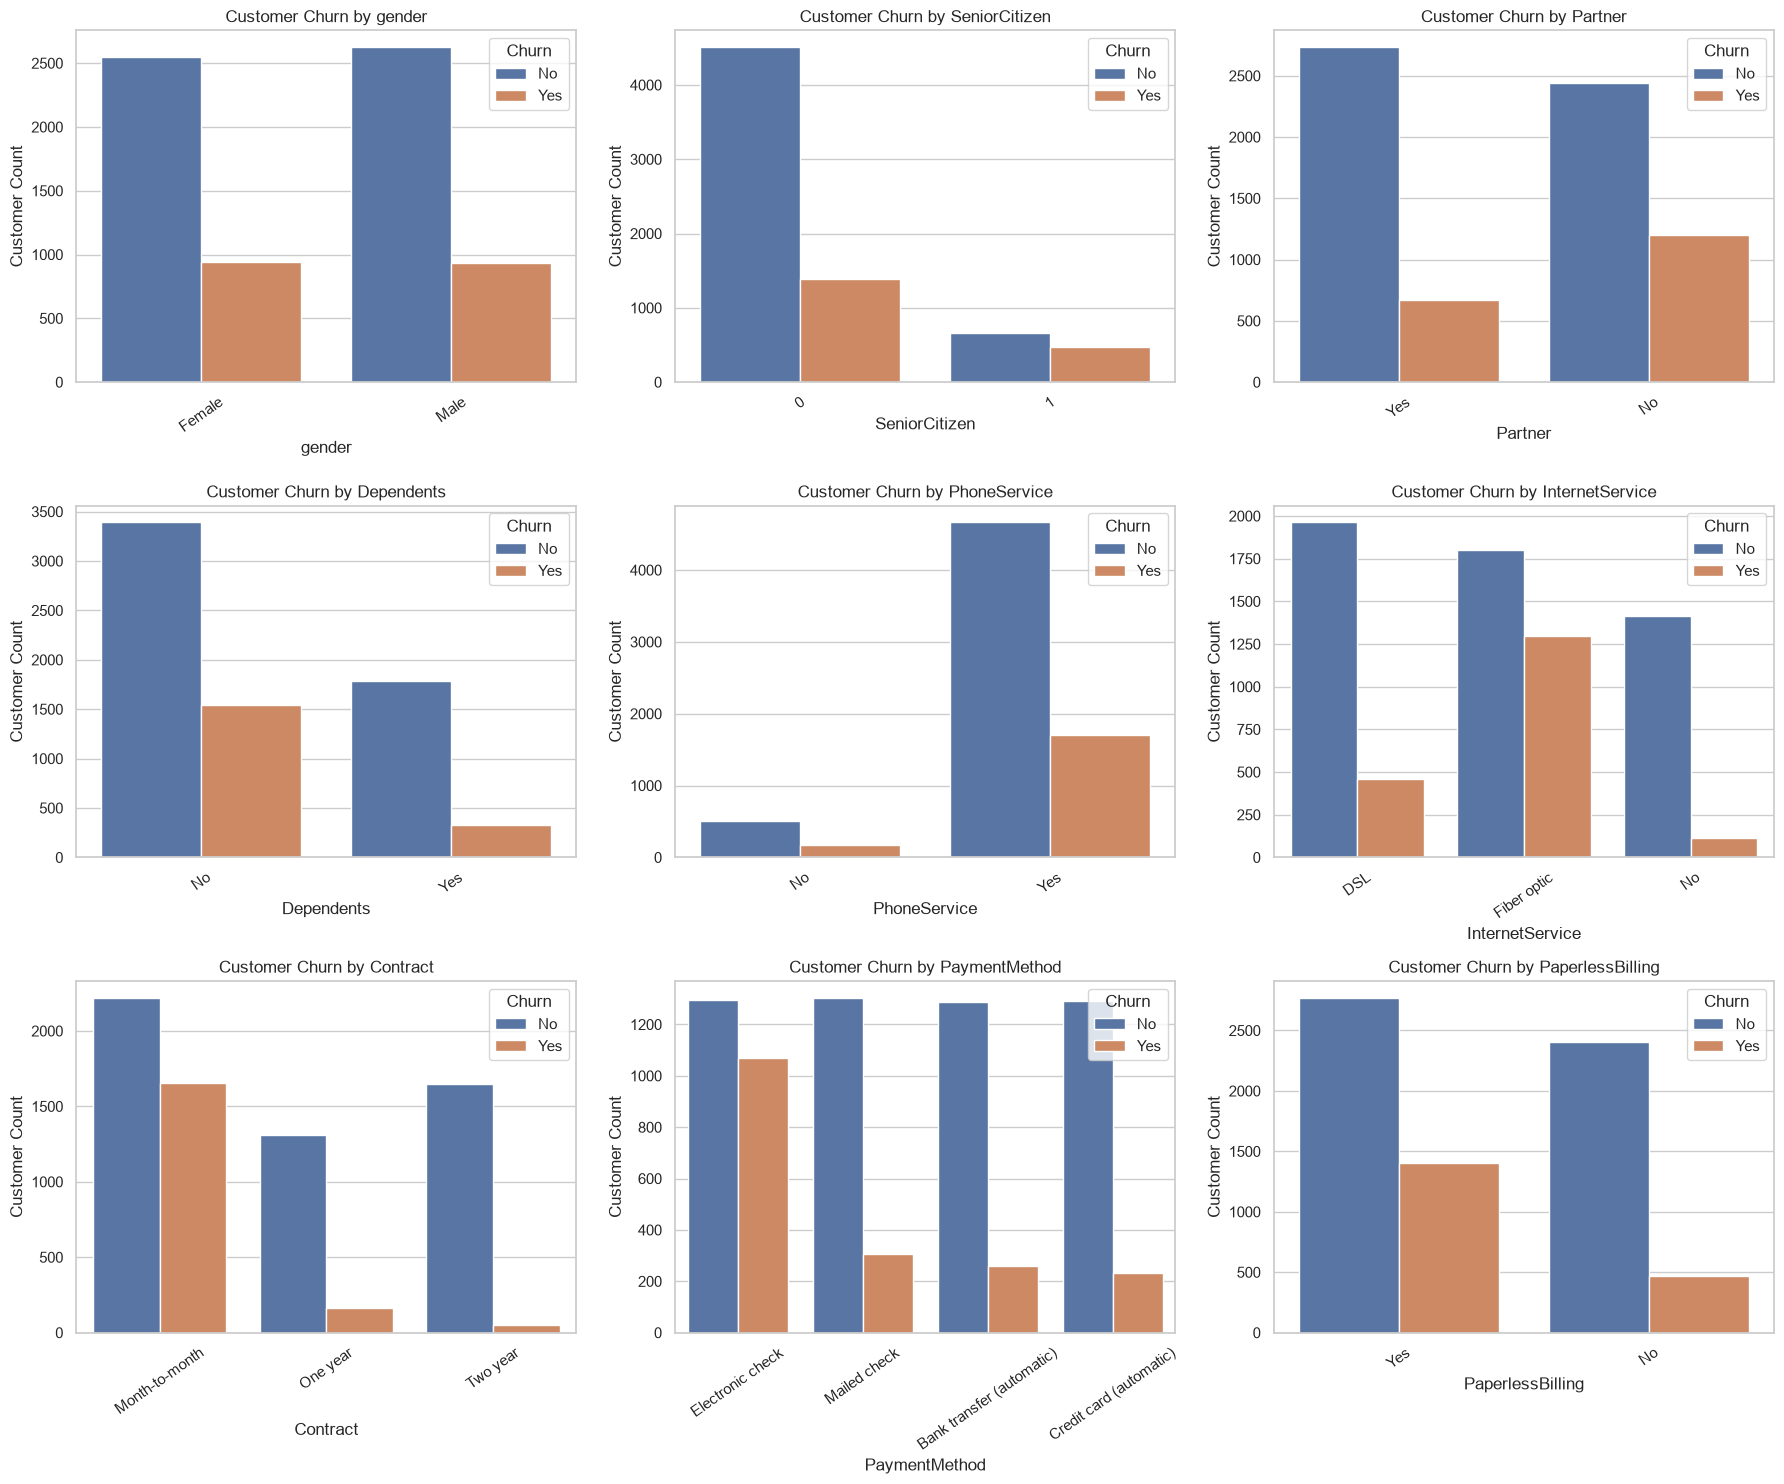

In [30]:

# ============================================================
# CELL 5: CUSTOMER DEMOGRAPHICS AND SERVICE ANALYSIS
# ============================================================

categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "InternetService",
    "Contract",
    "PaymentMethod",
    "PaperlessBilling"
]

fig, axes = plt.subplots(3, 3, figsize=(18, 15))

for column, ax in zip(categorical_features, axes.flatten()):

    sns.countplot(
        data=df,
        x=column,
        hue="Churn",
        ax=ax
    )

    ax.set_title(f"Customer Churn by {column}")
    ax.tick_params(axis="x", rotation=35)
    ax.set_xlabel(column)
    ax.set_ylabel("Customer Count")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "02_customer_demographics.png",
    dpi=300
)

plt.show()


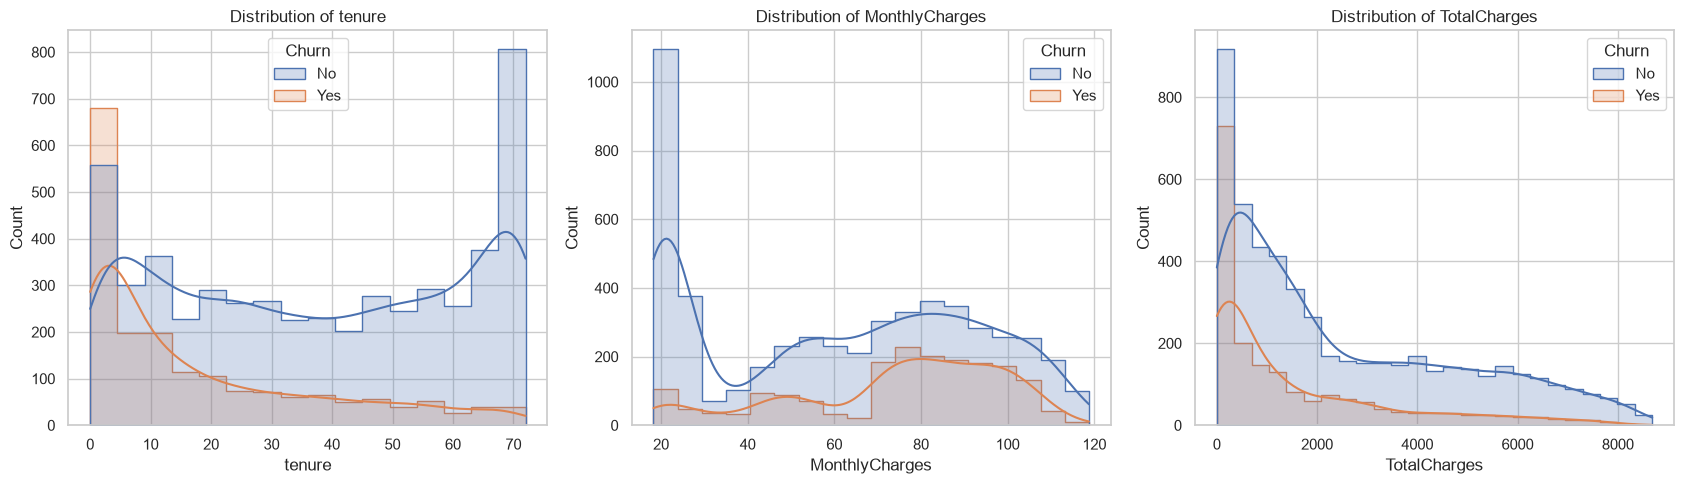

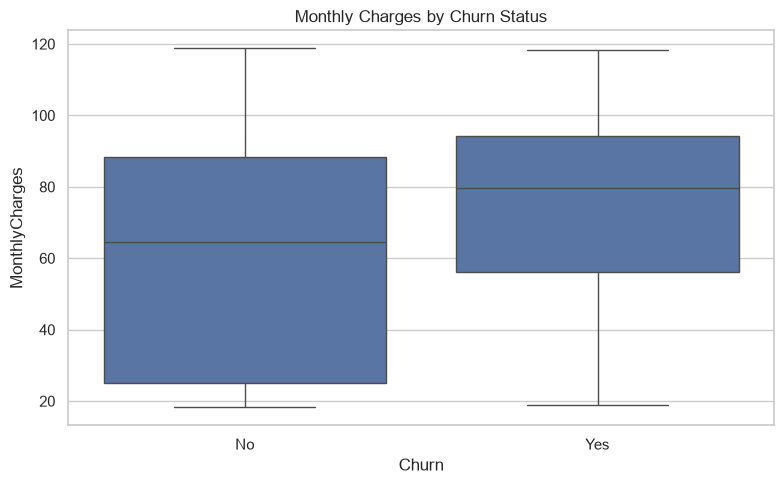

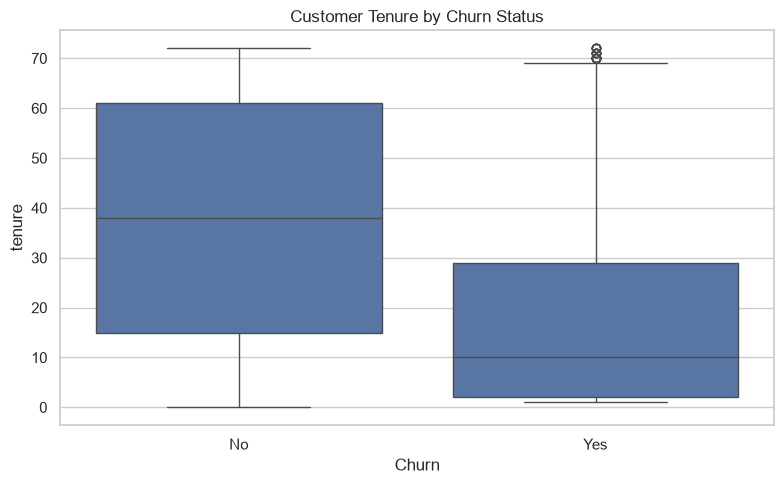

In [31]:

# ============================================================
# CELL 6: NUMERICAL FEATURE ANALYSIS
# ============================================================

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for column, ax in zip(numerical_features, axes):

    sns.histplot(
        data=df,
        x=column,
        hue="Churn",
        kde=True,
        element="step",
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "03_numerical_distributions.png",
    dpi=300
)

plt.show()

# Monthly charges by churn status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_monthly_charges_by_churn.png",
    dpi=300
)

plt.show()

# Tenure by churn status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_tenure_by_churn.png",
    dpi=300
)

plt.show()



Churn Rate by Contract:


,Churn Rate (%)
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


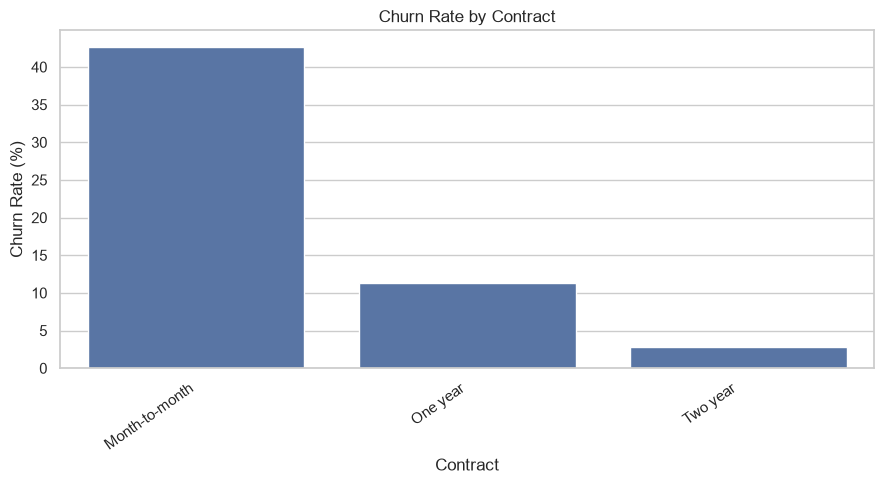


Churn Rate by PaymentMethod:


,Churn Rate (%)
PaymentMethod,
Electronic check,45.285412
Mailed check,19.106700
Bank transfer (automatic),16.709845
Credit card (automatic),15.243101


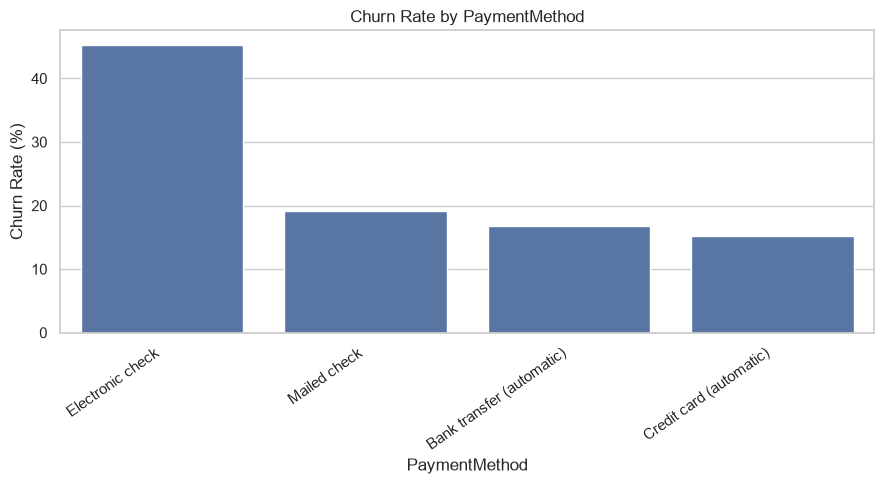


Churn Rate by InternetService:


,Churn Rate (%)
InternetService,
Fiber optic,41.892765
DSL,18.959108
No,7.404980


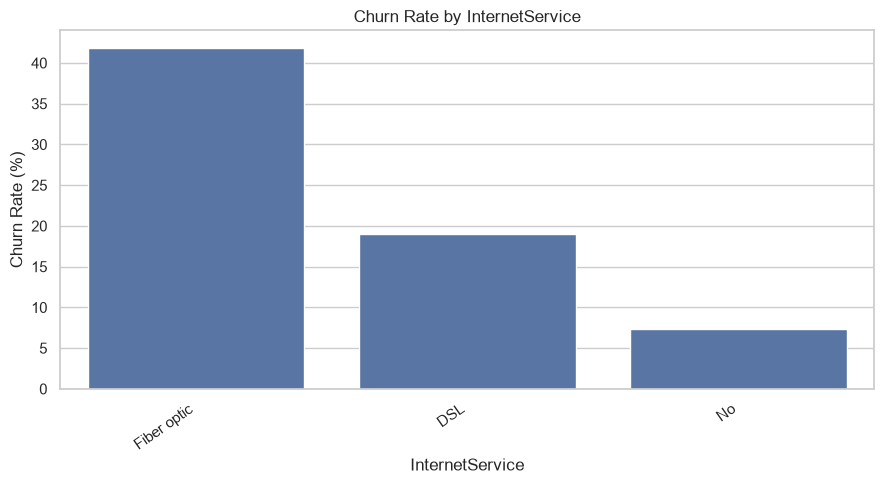


Churn Rate by TechSupport:


,Churn Rate (%)
TechSupport,
No,41.635474
Yes,15.166341
No internet service,7.404980


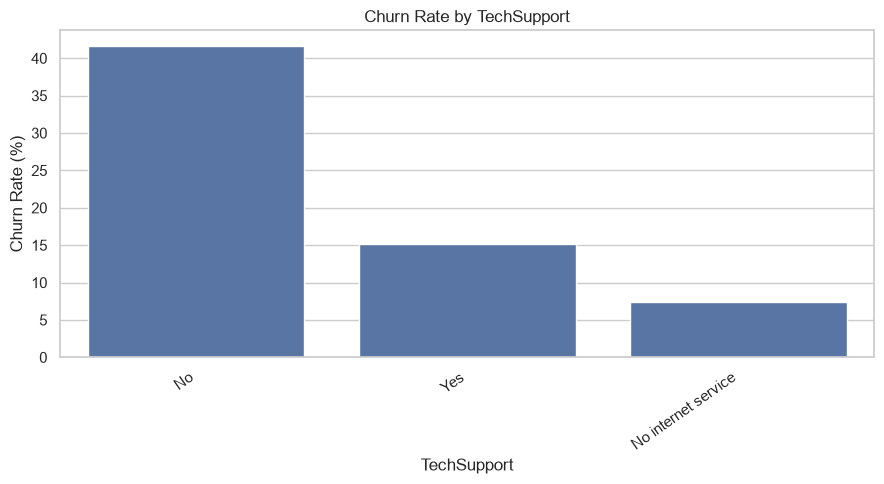


Churn Rate by OnlineSecurity:


,Churn Rate (%)
OnlineSecurity,
No,41.766724
Yes,14.611194
No internet service,7.404980


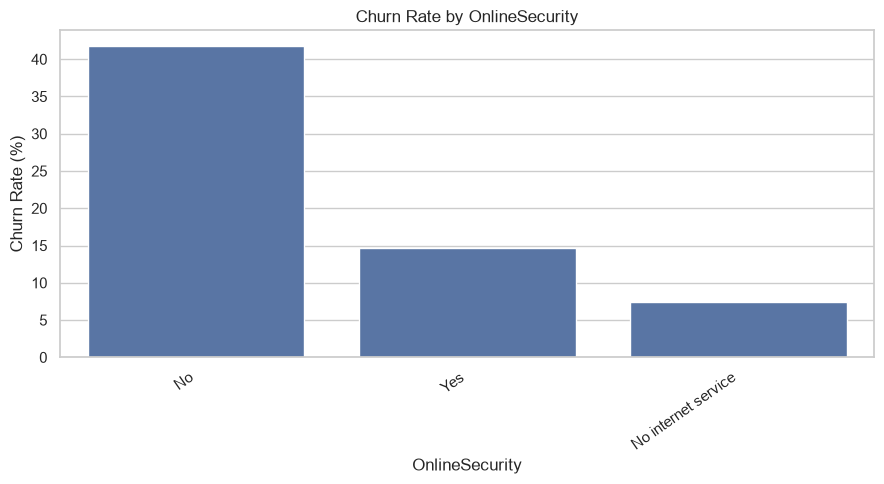

In [32]:

# ============================================================
# CELL 7: CHURN RATE BY BUSINESS FACTORS
# ============================================================

business_features = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "TechSupport",
    "OnlineSecurity"
]

for column in business_features:

    churn_rate = (
        df.groupby(column, observed=True)["Churn_Binary"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print(f"\nChurn Rate by {column}:")
    display(churn_rate.to_frame("Churn Rate (%)"))

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values
    )

    plt.title(f"Churn Rate by {column}")
    plt.ylabel("Churn Rate (%)")
    plt.xlabel(column)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    safe_name = column.replace(" ", "_")

    plt.savefig(
        FIGURE_DIR / f"06_churn_by_{safe_name}.png",
        dpi=300
    )

    plt.show()


In [33]:

# ============================================================
# CELL 8: CUSTOMER SEGMENTATION USING K-MEANS
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

segmentation_features = [
    "tenure",
    "MonthlyCharges",
    "SeniorCitizen"
]

X_segment = df[segmentation_features].copy()

# Scale the segmentation features
segment_scaler = StandardScaler()
X_segment_scaled = segment_scaler.fit_transform(X_segment)

# Find suitable number of clusters
cluster_results = []

for k in range(2, 9):

    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans_test.fit_predict(X_segment_scaled)

    score = silhouette_score(
        X_segment_scaled,
        labels
    )

    cluster_results.append({
        "Number of Clusters": k,
        "Silhouette Score": score,
        "Inertia": kmeans_test.inertia_
    })

cluster_results_df = pd.DataFrame(cluster_results)

display(cluster_results_df)

cluster_results_df.to_csv(
    OUTPUT_DIR / "kmeans_cluster_comparison.csv",
    index=False
)

# Select k with the highest silhouette score
best_k = int(
    cluster_results_df.loc[
        cluster_results_df["Silhouette Score"].idxmax(),
        "Number of Clusters"
    ]
)

print("Best number of clusters:", best_k)

# Train final K-Means
kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

df["Customer_Segment"] = kmeans_model.fit_predict(
    X_segment_scaled
)

final_silhouette = silhouette_score(
    X_segment_scaled,
    df["Customer_Segment"]
)

print("Final Silhouette Score:", round(final_silhouette, 4))

# Cluster profile
segment_profile = df.groupby(
    "Customer_Segment"
).agg(
    Customer_Count=("customerID", "count"),
    Average_Tenure=("tenure", "mean"),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Average_Total_Charges=("TotalCharges", "mean"),
    Churn_Rate=("Churn_Binary", "mean")
).round(2)

segment_profile["Churn_Rate"] = (
    segment_profile["Churn_Rate"] * 100
)

display(segment_profile)

segment_profile.to_csv(
    OUTPUT_DIR / "customer_segment_profile.csv"
)

df.to_csv(
    PROCESSED_DIR / "Telco_Customer_Churn_With_Segments.csv",
    index=False
)


,Number of Clusters,Silhouette Score,Inertia
0,2,0.471680,13742.648394
1,3,0.423390,8462.491202
2,4,0.445881,5785.057441
3,5,0.470716,4214.268310
4,6,0.472360,3292.136492
5,7,0.452953,2881.356951
6,8,0.429456,2495.518883


Best number of clusters: 6
Final Silhouette Score: 0.4724


,Customer_Count,Average_Tenure,Average_Monthly_Charges,Average_Total_Charges,Churn_Rate
Customer_Segment,,,,,
0,1547,10.11,31.16,298.52,23.0
1,1758,14.97,79.43,1188.97,45.0
2,515,56.72,87.96,4966.68,24.0
3,1548,59.06,92.08,5448.23,13.0
4,627,14.05,73.14,1039.41,56.0
5,1048,53.98,33.00,1775.51,4.0


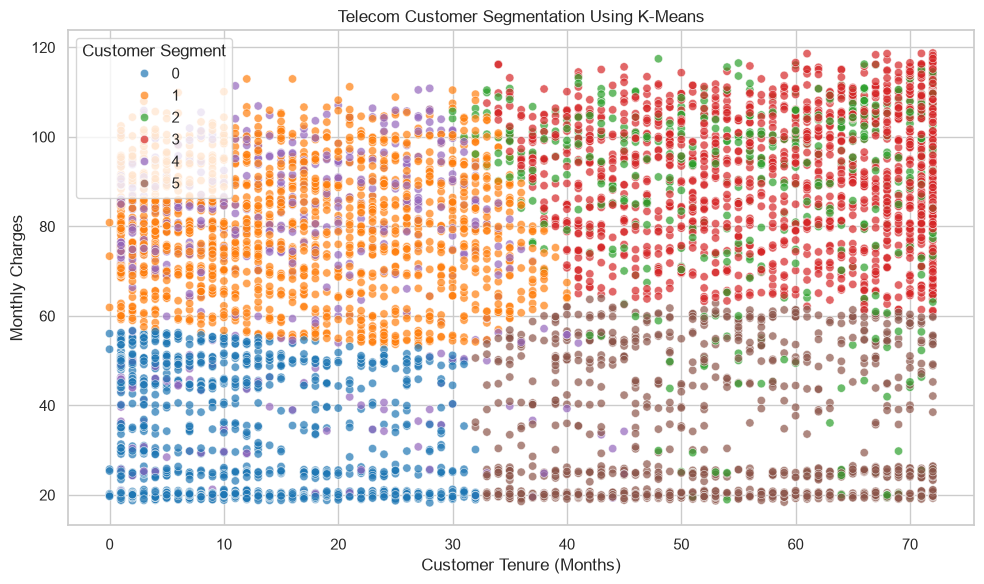

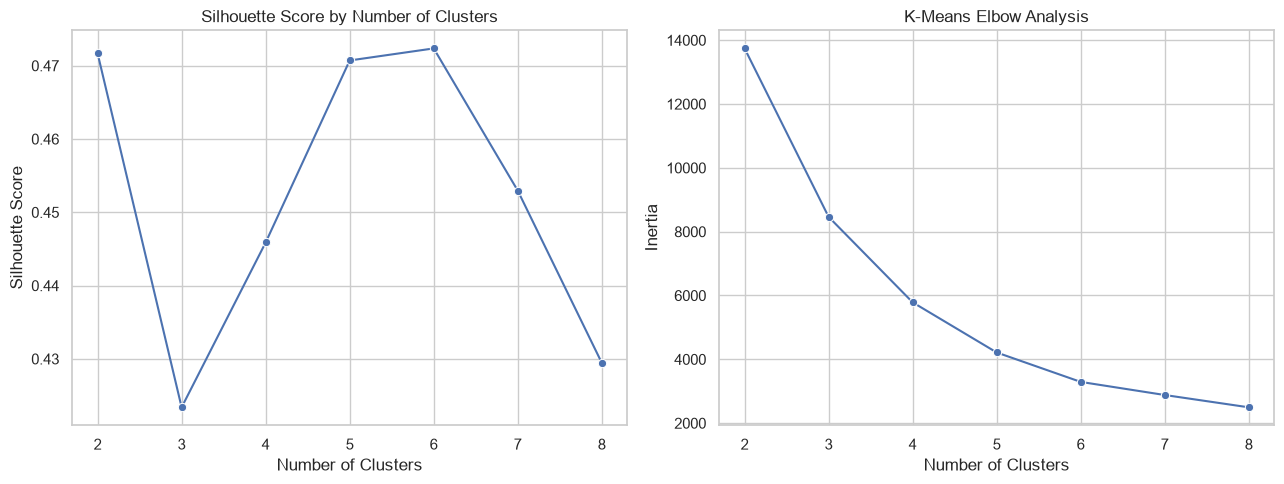

In [34]:

# ============================================================
# CELL 9: CUSTOMER SEGMENT VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="Customer_Segment",
    palette="tab10",
    alpha=0.7
)

plt.title("Telecom Customer Segmentation Using K-Means")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Customer Segment")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "07_customer_segmentation.png",
    dpi=300
)

plt.show()

# Cluster evaluation graph
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.lineplot(
    data=cluster_results_df,
    x="Number of Clusters",
    y="Silhouette Score",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Silhouette Score by Number of Clusters")

sns.lineplot(
    data=cluster_results_df,
    x="Number of Clusters",
    y="Inertia",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("K-Means Elbow Analysis")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "08_kmeans_evaluation.png",
    dpi=300
)

plt.show()


In [35]:

# ============================================================
# CELL 10: TRAIN-TEST SPLIT AND PREPROCESSING
# ============================================================

# Remove customer ID and target variables from predictors
X = df.drop(
    columns=["customerID", "Churn", "Churn_Binary", "Customer_Segment"],
    errors="ignore"
)

y = df["Churn_Binary"]

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully!")


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Training records: 5634
Testing records: 1409

Training target distribution:
Churn_Binary
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn_Binary
0    0.735
1    0.265
Name: proportion, dtype: float64

Preprocessing pipeline created successfully!


In [36]:

# ============================================================
# CELL 11: BUILD MACHINE LEARNING MODELS
# ============================================================

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

print("Models created:")
for name in models:
    print("-", name)


Models created:
- Logistic Regression
- Random Forest


In [37]:

# ============================================================
# CELL 12: CROSS-VALIDATION AND MODEL TRAINING
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

fitted_models = {}
cv_results = {}
comparison_results = []

for name, estimator in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    pipeline.fit(X_train, y_train)

    fitted_models[name] = pipeline
    cv_results[name] = scores

    result = {
        "Model": name
    }

    for metric in scoring:

        values = scores[f"test_{metric}"]

        result[f"CV {metric} Mean"] = values.mean()
        result[f"CV {metric} Std"] = values.std()

    comparison_results.append(result)

    print("Cross-validation completed!")
    print("Mean ROC-AUC:", round(scores["test_roc_auc"].mean(), 4))

model_comparison = pd.DataFrame(comparison_results)

display(model_comparison)

model_comparison.to_csv(
    OUTPUT_DIR / "model_cross_validation_comparison.csv",
    index=False
)



Training: Logistic Regression
Cross-validation completed!
Mean ROC-AUC: 0.846

Training: Random Forest
Cross-validation completed!
Mean ROC-AUC: 0.837


,Model,CV roc_auc Mean,CV roc_auc Std,CV average_precision Mean,CV average_precision Std,CV precision Mean,CV precision Std,CV recall Mean,CV recall Std,CV f1 Mean,CV f1 Std
0,Logistic Regression,0.845953,0.012410,0.659985,0.019476,0.516933,0.018899,0.801338,0.037933,0.628257,0.023165
1,Random Forest,0.837043,0.008844,0.634100,0.024992,0.552297,0.012785,0.719064,0.029310,0.624629,0.018303


In [38]:

# ============================================================
# CELL 13: MODEL TEST EVALUATION
# ============================================================

test_results = []
test_predictions = {}

for name, pipeline in fitted_models.items():

    print("\nEvaluating:", name)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    test_predictions[name] = {
        "predictions": predictions,
        "probabilities": probabilities
    }

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(y_test, probabilities)
    }

    test_results.append(results)

test_comparison = pd.DataFrame(test_results)

display(
    test_comparison.round(4)
)

test_comparison.to_csv(
    OUTPUT_DIR / "model_test_performance.csv",
    index=False
)

# Select best model using CV ROC-AUC, not test-set tuning
best_model_name = max(
    cv_results,
    key=lambda name: cv_results[name]["test_roc_auc"].mean()
)

best_model = fitted_models[best_model_name]

print("\nSelected model based on cross-validation ROC-AUC:")
print(best_model_name)



Evaluating: Logistic Regression

Evaluating: Random Forest


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416,0.6327
1,Random Forest,0.7615,0.5385,0.7112,0.6129,0.8348,0.6341



Selected model based on cross-validation ROC-AUC:
Logistic Regression


Selected model: Logistic Regression

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Not Churned     0.9022    0.7217    0.8019      1035
     Churned     0.5043    0.7834    0.6136       374

    accuracy                         0.7381      1409
   macro avg     0.7032    0.7526    0.7078      1409
weighted avg     0.7966    0.7381    0.7519      1409



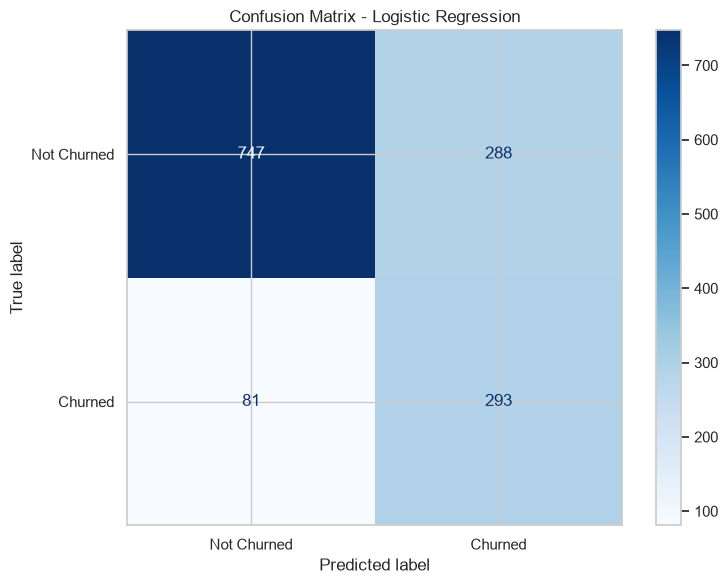

In [39]:

# ============================================================
# CELL 14: CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

best_predictions = test_predictions[best_model_name]["predictions"]
best_probabilities = test_predictions[best_model_name]["probabilities"]

print("Selected model:", best_model_name)

print("\nCLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Not Churned", "Churned"],
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churned", "Churned"]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "09_confusion_matrix.png",
    dpi=300
)

plt.show()


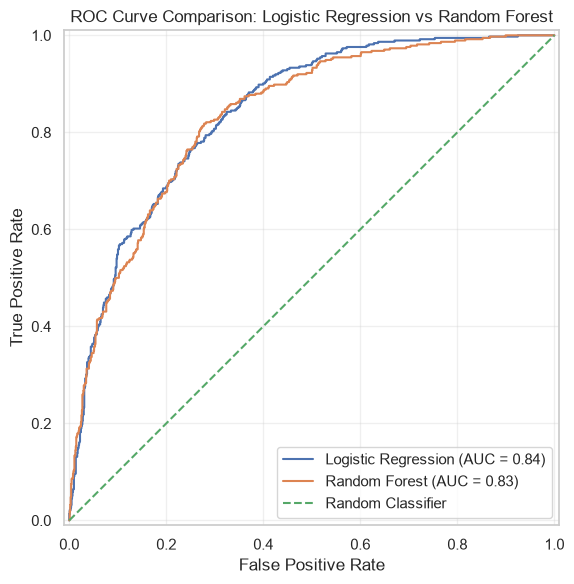

ROC comparison graph saved successfully!


In [46]:

# ============================================================
# CELL 15: ROC CURVE COMPARISON - CORRECTED
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

for name, pipeline in fitted_models.items():

    RocCurveDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_title("ROC Curve Comparison: Logistic Regression vs Random Forest")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "10_roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC comparison graph saved successfully!")


,Feature,Importance,Importance_Std
4,tenure,0.154458,0.001557
7,InternetService,0.049405,0.006602
14,Contract,0.035894,0.003153
17,MonthlyCharges,0.034009,0.006224
18,TotalCharges,0.013167,0.001778
13,StreamingMovies,0.005734,0.002208
12,StreamingTV,0.005342,0.001439
8,OnlineSecurity,0.004463,0.001883
11,TechSupport,0.003949,0.000842
16,PaymentMethod,0.003218,0.001189


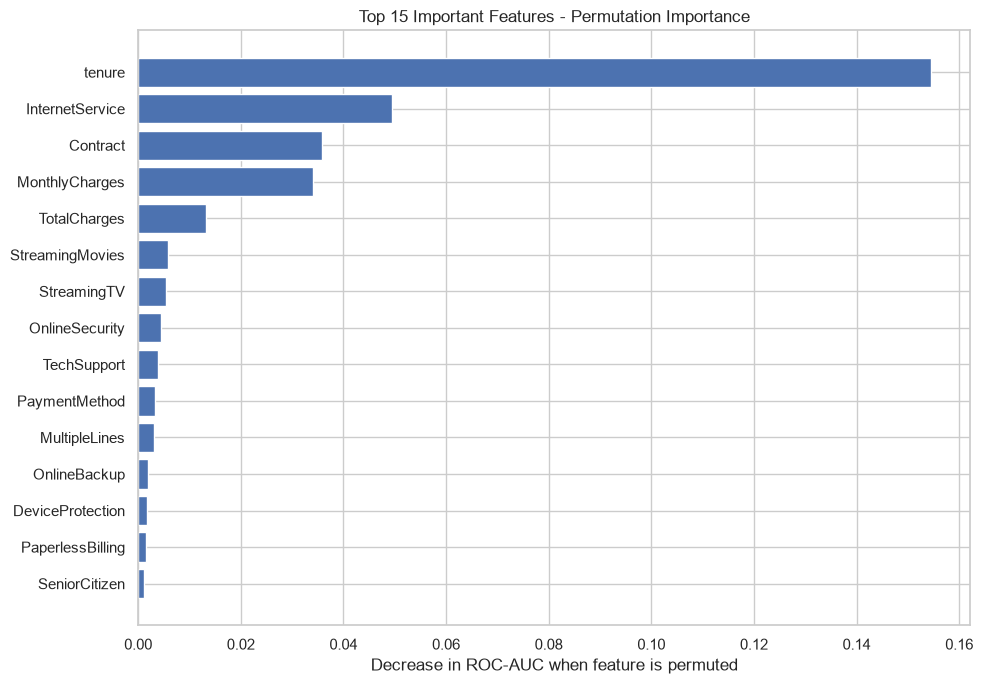

In [41]:

# ============================================================
# CELL 16: FEATURE IMPORTANCE
# ============================================================

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

plt.figure(figsize=(10, 7))

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Important Features - Permutation Importance")
plt.xlabel("Decrease in ROC-AUC when feature is permuted")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "11_feature_importance.png",
    dpi=300
)

plt.show()


In [42]:

# ============================================================
# CELL 17: BUSINESS INSIGHTS
# ============================================================

print("TELECOM CUSTOMER CHURN BUSINESS INSIGHTS")
print("=" * 60)

overall_churn_rate = df["Churn_Binary"].mean() * 100

print(
    "\nOverall customer churn rate:",
    round(overall_churn_rate, 2), "%"
)

# Churn rate by contract
contract_insights = (
    df.groupby("Contract")["Churn_Binary"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "Customers",
        "mean": "Churn Rate"
    })
)

contract_insights["Churn Rate"] *= 100

print("\nChurn by Contract:")
display(contract_insights.round(2))

# Churn rate by payment method
payment_insights = (
    df.groupby("PaymentMethod")["Churn_Binary"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("\nChurn by Payment Method:")
display(payment_insights.to_frame("Churn Rate (%)").round(2))

# Churn rate by internet service
internet_insights = (
    df.groupby("InternetService")["Churn_Binary"]
    .mean()
    .mul(100)
)

print("\nChurn by Internet Service:")
display(internet_insights.to_frame("Churn Rate (%)").round(2))

# Churn rate by tenure group
df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

tenure_insights = (
    df.groupby("Tenure_Group", observed=True)["Churn_Binary"]
    .mean()
    .mul(100)
)

print("\nChurn by Tenure Group:")
display(tenure_insights.to_frame("Churn Rate (%)").round(2))

# Export business insights
contract_insights.to_csv(
    OUTPUT_DIR / "churn_by_contract.csv"
)

payment_insights.to_csv(
    OUTPUT_DIR / "churn_by_payment_method.csv"
)

internet_insights.to_csv(
    OUTPUT_DIR / "churn_by_internet_service.csv"
)

tenure_insights.to_csv(
    OUTPUT_DIR / "churn_by_tenure.csv"
)

print("\nBusiness insight reports exported successfully!")


TELECOM CUSTOMER CHURN BUSINESS INSIGHTS

Overall customer churn rate: 26.54 %

Churn by Contract:


,Customers,Churn Rate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83



Churn by Payment Method:


,Churn Rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24



Churn by Internet Service:


,Churn Rate (%)
InternetService,
DSL,18.96
Fiber optic,41.89
No,7.40



Churn by Tenure Group:


,Churn Rate (%)
Tenure_Group,
0-12 months,47.44
13-24 months,28.71
25-48 months,20.39
49-72 months,9.51



Business insight reports exported successfully!


In [43]:

# ============================================================
# CELL 18: CUSTOMER CHURN PREDICTION EXPORT
# ============================================================

prediction_output = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Predicted_Churn": best_predictions,
    "Churn_Probability": best_probabilities
})

prediction_output["Actual_Churn"] = (
    prediction_output["Actual_Churn"].map({0: "No", 1: "Yes"})
)

prediction_output["Predicted_Churn"] = (
    prediction_output["Predicted_Churn"].map({0: "No", 1: "Yes"})
)

prediction_output["Risk_Level"] = pd.cut(
    prediction_output["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"]
)

prediction_output.to_csv(
    OUTPUT_DIR / "customer_churn_predictions.csv",
    index=False
)

print("Prediction results exported successfully!")
display(prediction_output.head(10))


Prediction results exported successfully!


,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level
0,No,No,0.117724,Low
1,No,Yes,0.851900,High
2,No,No,0.146251,Low
3,No,Yes,0.660234,High
4,No,No,0.060450,Low
5,No,Yes,0.805081,High
6,No,Yes,0.696758,High
7,No,No,0.291761,Low
8,No,No,0.008960,Low
9,Yes,Yes,0.652229,High


In [44]:

# ============================================================
# CELL 19: SAVE FINAL MODEL
# ============================================================

model_path = MODEL_DIR / "telecom_customer_churn_model.joblib"

joblib.dump(
    best_model,
    model_path
)

print("Final model saved successfully!")
print("Model path:", model_path)

# Verify saved model
loaded_model = joblib.load(model_path)

print("\nSaved model loaded successfully!")

loaded_predictions = loaded_model.predict(X_test)

print(
    "Reloaded model accuracy:",
    round(accuracy_score(y_test, loaded_predictions) * 100, 2),
    "%"
)


Final model saved successfully!
Model path: /Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/models/telecom_customer_churn_model.joblib

Saved model loaded successfully!
Reloaded model accuracy: 73.81 %


In [45]:

# ============================================================
# CELL 20: FINAL PROJECT SUMMARY
# ============================================================

print("=" * 65)
print("TELECOM CUSTOMER CHURN ANALYTICS AND PREDICTION")
print("FINAL PROJECT SUMMARY")
print("=" * 65)

print("\nDATASET")
print("Total customers:", len(df))
print("Total features:", df.shape[1])

print("\nCUSTOMER SEGMENTATION")
print("Optimal number of clusters:", best_k)
print("Silhouette score:", round(final_silhouette, 4))

print("\nCHURN PREDICTION")
print("Selected model:", best_model_name)

best_result = test_comparison[
    test_comparison["Model"] == best_model_name
].iloc[0]

print("Accuracy:", round(best_result["Accuracy"] * 100, 2), "%")
print("Precision:", round(best_result["Precision"], 4))
print("Recall:", round(best_result["Recall"], 4))
print("F1 Score:", round(best_result["F1 Score"], 4))
print("ROC-AUC:", round(best_result["ROC-AUC"], 4))
print("Average Precision:", round(best_result["Average Precision"], 4))

print("\nOUTPUT LOCATIONS")
print("Cleaned data:", PROCESSED_DIR)
print("Graphs:", FIGURE_DIR)
print("Models:", MODEL_DIR)
print("Reports:", OUTPUT_DIR)

print("\nPROJECT PIPELINE EXECUTION COMPLETED!")
print("=" * 65)


TELECOM CUSTOMER CHURN ANALYTICS AND PREDICTION
FINAL PROJECT SUMMARY

DATASET
Total customers: 7043
Total features: 24

CUSTOMER SEGMENTATION
Optimal number of clusters: 6
Silhouette score: 0.4724

CHURN PREDICTION
Selected model: Logistic Regression
Accuracy: 73.81 %
Precision: 0.5043
Recall: 0.7834
F1 Score: 0.6136
ROC-AUC: 0.8416
Average Precision: 0.6327

OUTPUT LOCATIONS
Cleaned data: /Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/data/processed
Graphs: /Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/outputs/figures
Models: /Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/models
Reports: /Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/outputs

PROJECT PIPELINE EXECUTION COMPLETED!


In [47]:

# ============================================================
# CELL 21: BUSINESS RECOMMENDATIONS, LIMITATIONS AND REFLECTION
# ============================================================

# 1. Calculate important business findings

print("=" * 65)
print("BUSINESS RECOMMENDATIONS AND PROJECT REFLECTION")
print("=" * 65)

overall_churn = df["Churn_Binary"].mean() * 100

contract_rates = (
    df.groupby("Contract")["Churn_Binary"].mean() * 100
)

payment_rates = (
    df.groupby("PaymentMethod")["Churn_Binary"].mean() * 100
)

internet_rates = (
    df.groupby("InternetService")["Churn_Binary"].mean() * 100
)

tenure_groups = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-72 months"]
)

tenure_rates = (
    df.groupby(tenure_groups, observed=True)["Churn_Binary"].mean() * 100
)

# Identify highest-risk categories
highest_contract = contract_rates.idxmax()
highest_payment = payment_rates.idxmax()
highest_internet = internet_rates.idxmax()
highest_tenure = tenure_rates.idxmax()

# Identify lowest-risk categories
lowest_contract = contract_rates.idxmin()
lowest_tenure = tenure_rates.idxmin()

# Top features from permutation importance
top_features = importance_df.head(5)["Feature"].tolist()

# Retrieve selected model performance
selected_result = test_comparison[
    test_comparison["Model"] == best_model_name
].iloc[0]


# 2. Display key findings

print("\n1. KEY BUSINESS FINDINGS")
print("-" * 65)

print(f"Overall customer churn rate: {overall_churn:.2f}%")

print(
    f"Highest churn contract category: {highest_contract} "
    f"({contract_rates[highest_contract]:.2f}%)"
)

print(
    f"Highest churn payment category: {highest_payment} "
    f"({payment_rates[highest_payment]:.2f}%)"
)

print(
    f"Highest churn internet category: {highest_internet} "
    f"({internet_rates[highest_internet]:.2f}%)"
)

print(
    f"Highest churn tenure group: {highest_tenure} "
    f"({tenure_rates[highest_tenure]:.2f}%)"
)

print(
    f"Lowest churn contract category: {lowest_contract} "
    f"({contract_rates[lowest_contract]:.2f}%)"
)

print(
    f"Lowest churn tenure group: {lowest_tenure} "
    f"({tenure_rates[lowest_tenure]:.2f}%)"
)

print("\nTop five predictive features:")
for feature in top_features:
    print("-", feature)


# 3. Create business recommendations

recommendations = [
    (
        "1. Focus on Early Customer Retention",
        f"The {highest_tenure} tenure group has the highest observed "
        f"churn rate of {tenure_rates[highest_tenure]:.2f}%. "
        "The company should strengthen onboarding, early customer support "
        "and follow-up communication for new customers."
    ),

    (
        "2. Encourage Longer-Term Contracts",
        f"The {highest_contract} contract category has the highest "
        f"observed churn rate of {contract_rates[highest_contract]:.2f}%. "
        "The company can test suitable discounts, loyalty benefits and "
        "transparent annual or long-term contract options."
    ),

    (
        "3. Review Payment Experience",
        f"Customers using {highest_payment} have the highest observed "
        f"payment-method category churn rate of "
        f"{payment_rates[highest_payment]:.2f}%. "
        "The company should investigate billing complaints and provide "
        "convenient alternative payment options."
    ),

    (
        "4. Improve Internet Service Experience",
        f"The {highest_internet} internet-service category has the highest "
        f"observed churn rate of {internet_rates[highest_internet]:.2f}%. "
        "The company should review service quality, connectivity issues "
        "and customer support for this category."
    ),

    (
        "5. Use Predictive Churn Monitoring",
        f"The selected model is {best_model_name}, with a test ROC-AUC "
        f"of {selected_result['ROC-AUC']:.4f}. "
        "The company can use predicted churn probabilities to prioritize "
        "customers for retention campaigns after appropriate business validation."
    ),

    (
        "6. Apply Customer-Specific Retention Strategies",
        "Use customer segmentation results to develop different retention "
        "strategies for groups with different tenure, charges and churn patterns."
    )
]

print("\n2. BUSINESS RECOMMENDATIONS")
print("-" * 65)

for heading, description in recommendations:
    print("\n" + heading)
    print(description)


# 4. Project limitations

limitations = [
    "The analysis uses one publicly available telecom customer dataset. "
    "Its findings may not represent every telecom company or market.",

    "The dataset contains customer-level records rather than a complete "
    "time-series history of customer behaviour.",

    "The clustering model uses a limited set of numerical customer features. "
    "Other categorical service characteristics could provide additional "
    "segmentation information.",

    "K-Means clustering depends on the selected features, scaling method "
    "and distance-based cluster assumptions.",

    "Customer churn classes are imbalanced. Class weighting was used in "
    "the classification models, but further threshold analysis may be useful.",

    "Model predictions identify statistical associations and risks. "
    "They do not establish that a particular service or billing factor "
    "directly causes customer churn.",

    "The model has been evaluated on a held-out test sample from the same "
    "dataset. Performance should be validated on new real-world customer data."
]

print("\n3. PROJECT LIMITATIONS")
print("-" * 65)

for number, limitation in enumerate(limitations, start=1):
    print(f"{number}. {limitation}")


# 5. Reflective discussion

reflection = f"""
During this capstone project, I developed an end-to-end telecom customer
churn analytics and prediction workflow. I worked with customer data,
performed data cleaning, investigated missing and blank values, and
conducted exploratory data analysis to understand customer behaviour.

I applied K-Means clustering to identify customer segments and developed
Logistic Regression and Random Forest models to predict customer churn.
The selected model was {best_model_name}, which achieved a test ROC-AUC
of {selected_result['ROC-AUC']:.4f}.

The project helped me understand the importance of data preprocessing,
feature selection, class imbalance, model evaluation and interpretation.
It also showed how analytical findings can be translated into practical
business recommendations.

One important learning was that a model with good overall accuracy is
not necessarily sufficient for a customer retention problem. Recall,
precision, F1-score and ROC-AUC must also be considered when identifying
customers who may leave.

Further improvements could include testing additional models, tuning
classification thresholds, evaluating more customer features and
validating the model on newer customer records.
"""

print("\n4. REFLECTIVE DISCUSSION")
print("-" * 65)
print(reflection)


# 6. Export final project discussion

REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report_content = "# Telecom Customer Churn Capstone\n\n"

report_content += "## Key Business Findings\n\n"
report_content += f"- Overall churn rate: {overall_churn:.2f}%\n"
report_content += f"- Highest churn contract: {highest_contract} ({contract_rates[highest_contract]:.2f}%)\n"
report_content += f"- Highest churn payment method: {highest_payment} ({payment_rates[highest_payment]:.2f}%)\n"
report_content += f"- Highest churn internet category: {highest_internet} ({internet_rates[highest_internet]:.2f}%)\n"
report_content += f"- Highest churn tenure group: {highest_tenure} ({tenure_rates[highest_tenure]:.2f}%)\n\n"

report_content += "## Business Recommendations\n\n"

for heading, description in recommendations:
    report_content += f"### {heading}\n\n{description}\n\n"

report_content += "## Project Limitations\n\n"

for number, limitation in enumerate(limitations, start=1):
    report_content += f"{number}. {limitation}\n\n"

report_content += "## Reflective Discussion\n\n"
report_content += reflection

discussion_path = REPORT_DIR / "Business_Insights_and_Project_Reflection.md"

discussion_path.write_text(
    report_content,
    encoding="utf-8"
)

print("\nProject discussion exported successfully!")
print("Saved at:", discussion_path)


BUSINESS RECOMMENDATIONS AND PROJECT REFLECTION

1. KEY BUSINESS FINDINGS
-----------------------------------------------------------------
Overall customer churn rate: 26.54%
Highest churn contract category: Month-to-month (42.71%)
Highest churn payment category: Electronic check (45.29%)
Highest churn internet category: Fiber optic (41.89%)
Highest churn tenure group: 0-12 months (47.44%)
Lowest churn contract category: Two year (2.83%)
Lowest churn tenure group: 49-72 months (9.51%)

Top five predictive features:
- tenure
- InternetService
- Contract
- MonthlyCharges
- TotalCharges

2. BUSINESS RECOMMENDATIONS
-----------------------------------------------------------------

1. Focus on Early Customer Retention
The 0-12 months tenure group has the highest observed churn rate of 47.44%. The company should strengthen onboarding, early customer support and follow-up communication for new customers.

2. Encourage Longer-Term Contracts
The Month-to-month contract category has the highes

In [48]:

# ============================================================
# CELL 22: FINAL MODEL AND PROJECT FILE VERIFICATION
# ============================================================

import joblib
import numpy as np
import pandas as pd

# 1. Reload the saved model
print("=" * 65)
print("FINAL MODEL VERIFICATION")
print("=" * 65)

reloaded_model = joblib.load(model_path)

print("\nSaved model loaded successfully!")

# 2. Generate predictions using the reloaded model
reloaded_predictions = reloaded_model.predict(X_test)

reloaded_probabilities = reloaded_model.predict_proba(X_test)[:, 1]

# 3. Compare original and reloaded predictions
predictions_match = np.array_equal(
    best_predictions,
    reloaded_predictions
)

probabilities_match = np.allclose(
    best_probabilities,
    reloaded_probabilities
)

print("\nPrediction Verification:")
print("Original and reloaded predictions match:", predictions_match)
print("Original and reloaded probabilities match:", probabilities_match)

# 4. Verify model performance after reloading
reloaded_accuracy = accuracy_score(
    y_test,
    reloaded_predictions
)

reloaded_roc_auc = roc_auc_score(
    y_test,
    reloaded_probabilities
)

print("\nReloaded Model Performance:")
print("Accuracy:", round(reloaded_accuracy, 4))
print("ROC-AUC:", round(reloaded_roc_auc, 4))

# 5. List required project artifacts
required_files = [
    PROCESSED_DIR / "Telco_Customer_Churn_Cleaned.csv",
    PROCESSED_DIR / "Telco_Customer_Churn_With_Segments.csv",
    OUTPUT_DIR / "data_quality_report.csv",
    OUTPUT_DIR / "customer_segment_profile.csv",
    OUTPUT_DIR / "kmeans_cluster_comparison.csv",
    OUTPUT_DIR / "model_cross_validation_comparison.csv",
    OUTPUT_DIR / "model_test_performance.csv",
    OUTPUT_DIR / "feature_importance.csv",
    OUTPUT_DIR / "customer_churn_predictions.csv",
    OUTPUT_DIR / "Business_Insights_and_Project_Reflection.md",
    MODEL_DIR / "telecom_customer_churn_model.joblib",
    FIGURE_DIR / "01_churn_distribution.png",
    FIGURE_DIR / "02_customer_demographics.png",
    FIGURE_DIR / "03_numerical_distributions.png",
    FIGURE_DIR / "07_customer_segmentation.png",
    FIGURE_DIR / "08_kmeans_evaluation.png",
    FIGURE_DIR / "09_confusion_matrix.png",
    FIGURE_DIR / "10_roc_curve_comparison.png",
    FIGURE_DIR / "11_feature_importance.png"
]

# 6. Verify every file
artifact_report = []

for file_path in required_files:

    exists = file_path.exists()

    artifact_report.append({
        "File Name": file_path.name,
        "Status": "Available" if exists else "Missing",
        "Size (KB)": (
            round(file_path.stat().st_size / 1024, 2)
            if exists else 0
        )
    })

artifact_df = pd.DataFrame(artifact_report)

print("\nPROJECT ARTIFACT VERIFICATION:")
display(artifact_df)

# 7. Save artifact verification report
artifact_df.to_csv(
    OUTPUT_DIR / "project_artifact_verification.csv",
    index=False
)

available = (artifact_df["Status"] == "Available").sum()
missing = (artifact_df["Status"] == "Missing").sum()

print("\nAvailable files:", available)
print("Missing files:", missing)

print("\nMODEL PREDICTIONS MATCH:", predictions_match)
print("MODEL PROBABILITIES MATCH:", probabilities_match)

print("\nVerification report saved successfully!")
print("Location:", OUTPUT_DIR / "project_artifact_verification.csv")

if predictions_match and probabilities_match and missing == 0:
    print("\nALL REQUIRED TECHNICAL CHECKS PASSED!")
else:
    print("\nSOME CHECKS NEED ATTENTION. Review the report above.")


FINAL MODEL VERIFICATION

Saved model loaded successfully!

Prediction Verification:
Original and reloaded predictions match: True
Original and reloaded probabilities match: True

Reloaded Model Performance:
Accuracy: 0.7381
ROC-AUC: 0.8416

PROJECT ARTIFACT VERIFICATION:


,File Name,Status,Size (KB)
0,Telco_Customer_Churn_Cleaned.csv,Available,962.90
1,Telco_Customer_Churn_With_Segments.csv,Available,976.67
2,data_quality_report.csv,Available,0.61
3,customer_segment_profile.csv,Available,0.30
4,kmeans_cluster_comparison.csv,Available,0.32
5,model_cross_validation_comparison.csv,Available,0.59
6,model_test_performance.csv,Available,0.32
7,feature_importance.csv,Available,1.07
8,customer_churn_predictions.csv,Available,42.92
9,Business_Insights_and_Project_Reflection.md,Missing,0.00



Available files: 18
Missing files: 1

MODEL PREDICTIONS MATCH: True
MODEL PROBABILITIES MATCH: True

Verification report saved successfully!
Location: /Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/outputs/project_artifact_verification.csv

SOME CHECKS NEED ATTENTION. Review the report above.


,Customer_Count,Average_Churn_Probability,Actual_Churn_Rate
Risk_Level,,,
High,2350,77.47,56.68
Medium,1718,44.81,23.57
Low,2975,10.98,4.44



TOP 20 CUSTOMERS WITH HIGHEST PREDICTED CHURN RISK


,Customer_ID,Tenure_Months,Contract,Monthly_Charges,Churn_Probability_Percent,Risk_Level
1976,9497-QCMMS,1,Month-to-month,93.55,93.88,High
4800,9300-AGZNL,1,Month-to-month,94.00,93.82,High
3380,5178-LMXOP,1,Month-to-month,95.10,93.78,High
3749,4424-TKOPW,2,Month-to-month,93.85,93.69,High
6368,2720-WGKHP,2,Month-to-month,94.00,93.65,High
5989,5567-WSELE,3,Month-to-month,94.60,93.53,High
1410,7024-OHCCK,2,Month-to-month,93.85,93.47,High
3159,5150-ITWWB,3,Month-to-month,94.85,93.45,High
2208,7216-EWTRS,1,Month-to-month,100.80,93.20,High
997,1374-DMZUI,4,Month-to-month,94.30,93.16,High


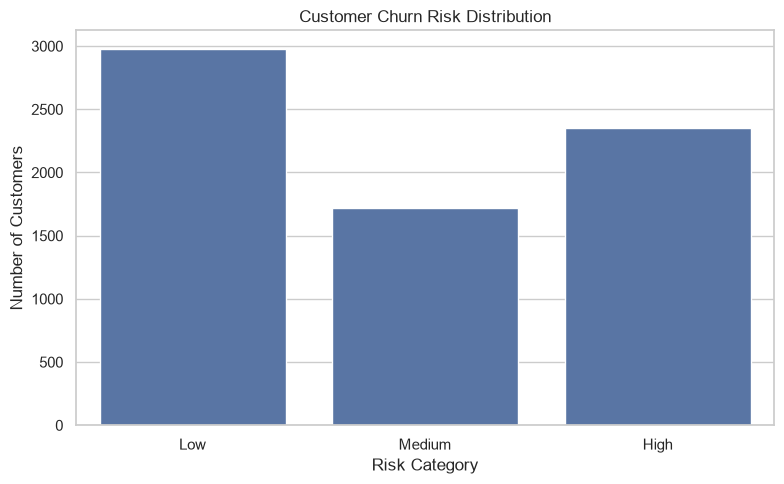


Customer risk register saved successfully!
File: /Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/outputs/customer_churn_risk_register.csv


In [49]:

# ============================================================
# CELL 23: CUSTOMER CHURN RISK REGISTER
# ============================================================

# Predict churn probabilities for all customers
all_churn_probabilities = best_model.predict_proba(X)[:, 1]

all_churn_predictions = (
    all_churn_probabilities >= 0.5
).astype(int)

# Assign customer risk categories
risk_levels = np.select(
    [
        all_churn_probabilities < 0.30,
        all_churn_probabilities < 0.60
    ],
    [
        "Low",
        "Medium"
    ],
    default="High"
)

# Create customer risk register
risk_register = pd.DataFrame({
    "Customer_ID": df["customerID"].values,
    "Tenure_Months": df["tenure"].values,
    "Contract": df["Contract"].values,
    "Monthly_Charges": df["MonthlyCharges"].values,
    "Churn_Probability": all_churn_probabilities,
    "Predicted_Churn": all_churn_predictions,
    "Risk_Level": risk_levels,
    "Actual_Churn": df["Churn"].values
})

risk_register["Churn_Probability_Percent"] = (
    risk_register["Churn_Probability"] * 100
).round(2)

# Sort customers by predicted churn probability
risk_register = risk_register.sort_values(
    by="Churn_Probability",
    ascending=False
)

# Save complete risk register
risk_register.to_csv(
    OUTPUT_DIR / "customer_churn_risk_register.csv",
    index=False
)

# Risk category summary
risk_summary = risk_register.groupby(
    "Risk_Level"
).agg(
    Customer_Count=("Customer_ID", "count"),
    Average_Churn_Probability=("Churn_Probability_Percent", "mean"),
    Actual_Churn_Rate=(
        "Actual_Churn",
        lambda x: (x == "Yes").mean() * 100
    )
).round(2)

risk_summary = risk_summary.reindex(
    ["High", "Medium", "Low"]
)

display(risk_summary)

# Save risk summary
risk_summary.to_csv(
    OUTPUT_DIR / "customer_risk_summary.csv"
)

# Display the 20 highest-risk customers
print("\nTOP 20 CUSTOMERS WITH HIGHEST PREDICTED CHURN RISK")

display(
    risk_register[
        [
            "Customer_ID",
            "Tenure_Months",
            "Contract",
            "Monthly_Charges",
            "Churn_Probability_Percent",
            "Risk_Level"
        ]
    ].head(20)
)

# Visualize risk distribution
risk_counts = (
    risk_register["Risk_Level"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "12_customer_churn_risk_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nCustomer risk register saved successfully!")
print("File:", OUTPUT_DIR / "customer_churn_risk_register.csv")


CHURN PREDICTION THRESHOLD COMPARISON


,Threshold,Accuracy,Precision,Recall,F1 Score,Specificity,Customers Flagged,True Positives,False Positives,False Negatives
0,0.3,0.6544,0.4300,0.9278,0.5876,0.5556,807,347,460,27
1,0.4,0.7012,0.4662,0.8663,0.6062,0.6415,695,324,371,50
2,0.5,0.7381,0.5043,0.7834,0.6136,0.7217,581,293,288,81
3,0.6,0.7622,0.5399,0.7059,0.6118,0.7826,489,264,225,110
4,0.7,0.7885,0.6016,0.6016,0.6016,0.8560,374,225,149,149


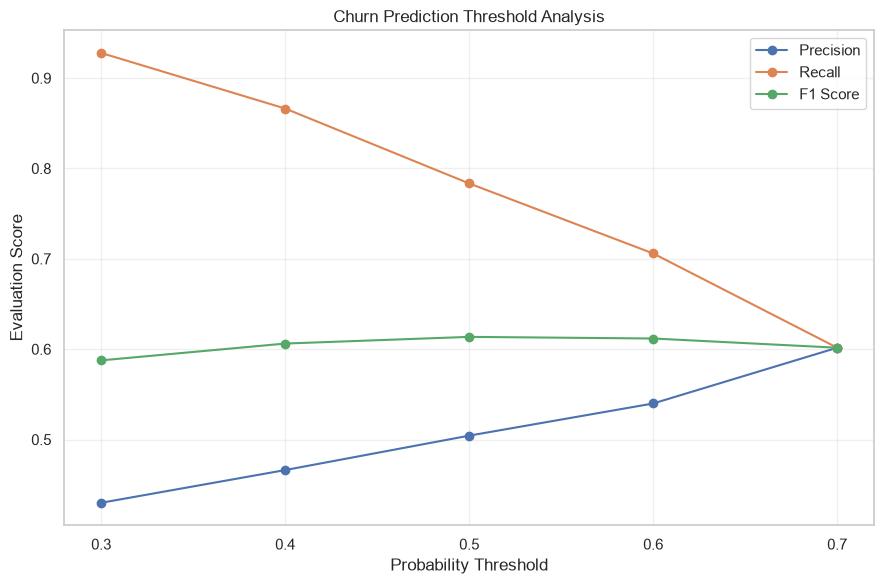


Threshold analysis exported successfully!
Saved: churn_threshold_analysis.csv
Saved: 13_threshold_analysis.png


In [50]:

# ============================================================
# CELL 24: CHURN PREDICTION THRESHOLD ANALYSIS
# ============================================================

# Test different probability thresholds
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into binary predictions
    threshold_predictions = (
        best_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        threshold_predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics
    accuracy = accuracy_score(
        y_test,
        threshold_predictions
    )

    precision = precision_score(
        y_test,
        threshold_predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        threshold_predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        threshold_predictions,
        zero_division=0
    )

    specificity = tn / (tn + fp) if (tn + fp) else 0

    flagged = int(threshold_predictions.sum())

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4),
        "Specificity": round(specificity, 4),
        "Customers Flagged": flagged,
        "True Positives": int(tp),
        "False Positives": int(fp),
        "False Negatives": int(fn)
    })

# Create comparison table
threshold_df = pd.DataFrame(threshold_results)

print("CHURN PREDICTION THRESHOLD COMPARISON")
print("=" * 70)

display(threshold_df)

# Export threshold analysis
threshold_df.to_csv(
    OUTPUT_DIR / "churn_threshold_analysis.csv",
    index=False
)

# Plot precision, recall and F1 score
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Evaluation Score")
plt.title("Churn Prediction Threshold Analysis")
plt.xticks(thresholds)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "13_threshold_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nThreshold analysis exported successfully!")
print("Saved: churn_threshold_analysis.csv")
print("Saved: 13_threshold_analysis.png")


In [51]:

# ============================================================
# CELL 25: FINAL WEEK 6 PROJECT AUDIT
# ============================================================

import pandas as pd
from pathlib import Path

print("=" * 70)
print("WEEK 6 CAPSTONE PROJECT - FINAL AUDIT")
print("=" * 70)

# 1. Verify important project files
expected_files = [
    PROCESSED_DIR / "Telco_Customer_Churn_Cleaned.csv",
    PROCESSED_DIR / "Telco_Customer_Churn_With_Segments.csv",
    OUTPUT_DIR / "data_quality_report.csv",
    OUTPUT_DIR / "customer_segment_profile.csv",
    OUTPUT_DIR / "kmeans_cluster_comparison.csv",
    OUTPUT_DIR / "model_cross_validation_comparison.csv",
    OUTPUT_DIR / "model_test_performance.csv",
    OUTPUT_DIR / "feature_importance.csv",
    OUTPUT_DIR / "customer_churn_predictions.csv",
    OUTPUT_DIR / "customer_churn_risk_register.csv",
    OUTPUT_DIR / "customer_risk_summary.csv",
    OUTPUT_DIR / "churn_threshold_analysis.csv",
    REPORT_DIR / "Business_Insights_and_Project_Reflection.md",
    MODEL_DIR / "telecom_customer_churn_model.joblib",
    FIGURE_DIR / "01_churn_distribution.png",
    FIGURE_DIR / "02_customer_demographics.png",
    FIGURE_DIR / "03_numerical_distributions.png",
    FIGURE_DIR / "07_customer_segmentation.png",
    FIGURE_DIR / "08_kmeans_evaluation.png",
    FIGURE_DIR / "09_confusion_matrix.png",
    FIGURE_DIR / "10_roc_curve_comparison.png",
    FIGURE_DIR / "11_feature_importance.png",
    FIGURE_DIR / "12_customer_churn_risk_distribution.png",
    FIGURE_DIR / "13_threshold_analysis.png"
]

audit_results = []

for file_path in expected_files:
    exists = file_path.is_file()

    audit_results.append({
        "File": file_path.name,
        "Status": "Available" if exists else "Missing",
        "Size (KB)": (
            round(file_path.stat().st_size / 1024, 2)
            if exists else 0
        )
    })

audit_df = pd.DataFrame(audit_results)

display(audit_df)

available_count = (audit_df["Status"] == "Available").sum()
missing_count = (audit_df["Status"] == "Missing").sum()

print("\nFiles available:", available_count)
print("Files missing:", missing_count)


# 2. Verify important analytical outputs

print("\n" + "=" * 70)
print("PROJECT RESULTS SUMMARY")
print("=" * 70)

print("Dataset records:", len(df))
print("Dataset columns:", len(df.columns))

print(
    "Overall churn rate:",
    round(df["Churn_Binary"].mean() * 100, 2), "%"
)

print("Number of customer segments:", best_k)

print(
    "K-Means silhouette score:",
    round(final_silhouette, 4)
)

print("Selected prediction model:", best_model_name)

print(
    "Test accuracy:",
    round(selected_result["Accuracy"] * 100, 2), "%"
)

print(
    "Test ROC-AUC:",
    round(selected_result["ROC-AUC"], 4)
)

print(
    "Test F1-score:",
    round(selected_result["F1 Score"], 4)
)

print("\nRisk register records:", len(risk_register))
print("Threshold comparisons:", len(threshold_df))


# 3. Verify customer prediction export

prediction_file = OUTPUT_DIR / "customer_churn_predictions.csv"

if prediction_file.exists():
    saved_predictions = pd.read_csv(prediction_file)

    print("\nSaved prediction records:", len(saved_predictions))
    print("Prediction columns:", saved_predictions.columns.tolist())


# 4. Save audit report

audit_df.to_csv(
    OUTPUT_DIR / "final_project_audit.csv",
    index=False
)

print("\nAudit report saved:")
print(OUTPUT_DIR / "final_project_audit.csv")


# 5. Final status
if missing_count == 0:
    print("\nALL EXPECTED PROJECT FILES ARE AVAILABLE!")
else:
    print("\nATTENTION: SOME PROJECT FILES ARE MISSING.")
    print("Please review the audit table before submission.")

print("\nFINAL AUDIT COMPLETED!")


WEEK 6 CAPSTONE PROJECT - FINAL AUDIT


,File,Status,Size (KB)
0,Telco_Customer_Churn_Cleaned.csv,Available,962.90
1,Telco_Customer_Churn_With_Segments.csv,Available,976.67
2,data_quality_report.csv,Available,0.61
3,customer_segment_profile.csv,Available,0.30
4,kmeans_cluster_comparison.csv,Available,0.32
5,model_cross_validation_comparison.csv,Available,0.59
6,model_test_performance.csv,Available,0.32
7,feature_importance.csv,Available,1.07
8,customer_churn_predictions.csv,Available,42.92
9,customer_churn_risk_register.csv,Available,461.82



Files available: 24
Files missing: 0

PROJECT RESULTS SUMMARY
Dataset records: 7043
Dataset columns: 24
Overall churn rate: 26.54 %
Number of customer segments: 6
K-Means silhouette score: 0.4724
Selected prediction model: Logistic Regression
Test accuracy: 73.81 %
Test ROC-AUC: 0.8416
Test F1-score: 0.6136

Risk register records: 7043
Threshold comparisons: 5

Saved prediction records: 1409
Prediction columns: ['Actual_Churn', 'Predicted_Churn', 'Churn_Probability', 'Risk_Level']

Audit report saved:
/Users/priyanshukumar/Documents/Internship/Week 6 Capstone Project/outputs/final_project_audit.csv

ALL EXPECTED PROJECT FILES ARE AVAILABLE!

FINAL AUDIT COMPLETED!
